<a href="https://colab.research.google.com/github/pk2942436-coder/public/blob/main/EXP_6_PATUP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_11845/724748504.py:17: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  time = pd.date_range(start='2015-01-01', periods=periods,


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  120
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -303.499
Date:                Sat, 14 Nov 2026   AIC                            612.997
Time:                        07:49:34   BIC                            621.335
Sample:                    01-31-2015   HQIC                           616.383
                         - 12-31-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4167      0.820     -0.508      0.612      -2.025       1.191
ma.L1          0.3230      0.864      0.374      0.708      -1.369       2.015
sigma2         9.6103      1.544      6.225      0.0

/tmp/ipykernel_11845/724748504.py:42: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  forecast_index = pd.date_range(start=series.index[-1] +


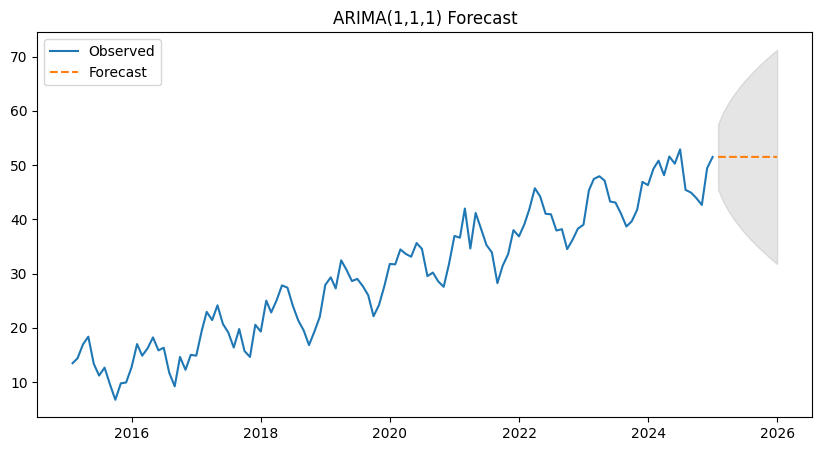

In [ ]:
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA

from statsmodels.tsa.stattools import adfuller

#(Reusing the synthetic series from previous experiment)

np.random.seed(42)

periods = 120

time = pd.date_range(start='2015-01-01', periods=periods,

freq='M')

trend = np.linspace(10, 50, periods)

seasonal=5* np.sin(2* np.pi* time.month/12)

noise = np.random.normal(0, 2, periods)

series = pd.Series(trend + seasonal + noise, index=time)

# Difference once to remove trend (d=1)

series_diff=series.diff().dropna()

# Fit ARIMA (p=1,d=1,q=1) as a simple example

model = ARIMA(series, order=(1,1,1))

model_fit=model.fit()

print(model_fit.summary())
forecast=model_fit.get_forecast(steps=12)

forecast_index = pd.date_range(start=series.index[-1] +

pd.offsets.MonthEnd(1), periods=12, freq='M')

forecast_mean = pd.Series(forecast.predicted_mean,

index=forecast_index)

conf_int=forecast.conf_int()

# Plot

plt.figure(figsize=(10,5))

plt.plot(series, label='Observed')

plt.plot(forecast_mean, label='Forecast', linestyle='--')

plt.fill_between(forecast_index, conf_int['lower y'],

conf_int['upper y'], color='gray', alpha=0.2)

plt.legend()

plt.title('ARIMA(1,1,1) Forecast')

plt.show()